# 6 · Investigación de Operaciones: repartir el presupuesto
**Torre del Caribe** · Universidad Nacional Rosario Castellanos · Licenciatura en Ciencia de Datos para Negocios, 5.º
semestre 2026-2 · Equipo 2

| | |
|---|---|
| **Materia (UCA)** | Investigación de Operaciones |
| **Profesor** | Carlos Orozco Rocha (tutor del equipo) |
| **Criterio de la rúbrica** | 6. Investigación de Operaciones (12 %) |
| **Equipo** | Brandon Uriel García Sánchez · Maribel Mondragón Mercado · Jesús Ramírez Isidro · Enrique González Ortega |

¿Cuánto dinero de la campaña va a cada lugar del sur, en qué mes y por qué canal, para traer el mayor
número de visitantes **sin anunciar donde ya está lleno, sin rebasar la capacidad de nadie y sin dejar a ninguna
comunidad fuera**? Empezamos con el modelo de dos variables por el método gráfico, como en clase, y lo extendemos al
modelo completo de 216 variables, que incluye la incertidumbre del notebook 5.

| Parte | Qué respondemos |
|---|---|
| 1. Los parámetros | ¿Cuántos visitantes trae un peso en cada canal? |
| 2. Método gráfico | El corazón del problema con dos variables |
| 3. El modelo completo | Estocástico de dos etapas, con PuLP y CBC |
| 4. ¿Cuánto cuesta cada regla? | Costo de las reglas, precios sombra y frontera de Pareto |
| 5. Sensibilidad | ¿Y si los supuestos están mal? ¿Por qué 15 % y 70 %? |
| 6. La etapa 2 semana a semana | El motor de la Torre en vivo |
| 7. Resumen de parámetros | Cada valor, por qué y qué descartamos |

**Cómo leer este notebook.** Antes de cada celda de código explicamos qué hacemos y por qué; dentro del código, cada
renglón lleva su comentario. Al terminar cada paso comparamos nuestro resultado con el que guardó el proyecto (función
`coincide`): si una cifra no coincidiera, el notebook se detendría ahí. El documento técnico del equipo
(*Torre_del_Caribe.pdf*) tiene las fórmulas con su ejemplo resuelto a mano.

**Cómo correrlo.** Python 3.11 con `pip install -r requirements.txt` desde la carpeta de la entrega; abrir en Jupyter o
VS Code y elegir *Ejecutar todo*. Ya viene ejecutado, así que también se puede leer sin correrlo.

In [1]:
%matplotlib inline
# Preparación. Buscamos la carpeta de la entrega (la que tiene datos/silver), cargamos las librerías,
# definimos el estilo de las gráficas y la función que compara nuestras cifras con las del proyecto.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

warnings.filterwarnings("ignore")                        # avisos de versiones de librerías que no cambian resultados
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos" / "silver").is_dir())
SILVER, GOLD = RAIZ / "datos" / "silver", RAIZ / "datos" / "gold"   # datos limpios y resultados del proyecto
FIGURAS = Path.cwd() / "figuras"                          # aquí guardamos cada gráfica como PNG
FIGURAS.mkdir(exist_ok=True)

# Colores institucionales de la UNRC (guinda y dorado) y una paleta para varias series.
GUINDA, DORADO, GRIS = "#9F2241", "#BC955C", "#3A3A3A"
PALETA = ["#9F2241", "#BC955C", "#565393", "#58A65D", "#8CAFDD", "#F26E50", "#465973"]
for f in (RAIZ / "herramientas" / "fuentes").glob("NotoSans-*.ttf"):
    font_manager.fontManager.addfont(str(f))          # la letra Noto Sans viene en la entrega
plt.rcParams.update({"font.family": "Noto Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlecolor": GUINDA, "axes.titlesize": 12,
                     "text.color": GRIS, "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
                     "figure.facecolor": "white", "savefig.dpi": 160, "savefig.bbox": "tight"})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)


def coincide(nombre, nuestro, proyecto, tolerancia=1e-6):
    """Compara un resultado de este notebook con el que guardó el proyecto. Si no coincide, se detiene."""
    a = np.asarray(nuestro, dtype=float).ravel()
    b = np.asarray(proyecto, dtype=float).ravel()
    assert a.shape == b.shape, f"{nombre}: tamaños distintos {a.shape} y {b.shape}"
    dif = float(np.nanmax(np.abs(a - b))) if len(a) else 0.0
    print(f"{'✓' if dif <= tolerancia else '✗'} {nombre}: coincide con el proyecto (diferencia máxima {dif:.2g})")
    assert dif <= tolerancia, f"{nombre} no coincide con el proyecto"


def guardar(fig, nombre):
    """Guarda la gráfica en figuras/ con un nombre claro."""
    fig.savefig(FIGURAS / f"{nombre}.png")


print("Carpeta de la entrega:", RAIZ)

Carpeta de la entrega: C:\Users\Uriel\Desktop\PP 5to semestre CASCO SANTO TOMAS\Entregable


## 1. Los parámetros: cuánto rinde un peso
Un anuncio es un embudo: muchas personas lo ven, algunas le dan clic y, de esas, algunas planean el viaje (conversión).
Se paga por clic. Lo que importa para decidir es cuántos visitantes trae cada peso:

$$r_c = \frac{\text{tasa de conversión}_c}{\text{costo por clic}_c\ (\text{dólares}) \times \text{pesos por dólar}}$$

Los costos por clic y la conversión son de la categoría viajes de WordStream by LocaliQ (2025), promedios de
anunciantes de Estados Unidos: los usamos como **supuesto etiquetado**, porque no existe un dato publicado para México.
El tipo de cambio es el último mes completo de FRED.

In [2]:
BENCH = sorted((RAIZ / "datos" / "bronze" / "benchmarks").glob("*/benchmarks_tablas.csv"))[-1]
bm = pd.read_csv(BENCH)
t = bm[bm.categoria == "Travel"].set_index(["clave_pagina", "metrica"]).valor
cpc_google = float(t["wordstream_google_2025", "Average CPC"])               # dólares por clic
cvr_google = float(t["wordstream_google_2025", "Average CVR"]) / 100           # conversiones por clic
cpc_facebook = float(t["wordstream_facebook_2025", "Average CPC"])
cvr_fb_mediana = round(float(bm[bm.clave_pagina.str.contains("facebook") & (bm.metrica == "Average CVR")].valor.median()) / 100, 4)
fx = pd.read_parquet(SILVER / "fred_mensual")
fx = fx[~fx.mes_incompleto_flag & fx.pesos_por_dolar.notna()].sort_values("periodo").iloc[-1]   # último mes completo
TC = float(fx.pesos_por_dolar)

def rendimiento(cvr_fb=None, cpc_fb=None):
    """Visitantes por peso en cada canal. Sin dato de conversión de Facebook para turismo, el caso base usa la de Google."""
    return {"Google": cvr_google / (cpc_google * TC),
            "Facebook": (cvr_google if cvr_fb is None else cvr_fb) / ((cpc_facebook if cpc_fb is None else cpc_fb) * TC)}
r = rendimiento()
print(f"Dólar {pd.Timestamp(fx.periodo):%m-%Y}: {TC:.4f} pesos")
print(f"Google: clic {cpc_google} USD = {cpc_google * TC:.2f} MXN, conversión {cvr_google:.2%} → {r['Google'] * 1000:.3f} visitantes por cada $1,000")
print(f"Facebook: clic {cpc_facebook} USD = {cpc_facebook * TC:.2f} MXN, conversión {cvr_google:.2%} (supuesto) → {r['Facebook'] * 1000:.3f} por cada $1,000")

Dólar 08-2026: 17.0609 pesos
Google: clic 2.12 USD = 36.17 MXN, conversión 5.75% → 1.590 visitantes por cada $1,000
Facebook: clic 0.51 USD = 8.70 MXN, conversión 5.75% (supuesto) → 6.608 por cada $1,000


Facebook rinde cuatro veces más por peso porque su clic es cuatro veces más barato, **con la misma
conversión supuesta**. Ese supuesto es el más débil del modelo (la conversión de Facebook para turismo no está
publicada), así que en la sección 5 lo movemos: 3 %, la mediana de todas las industrias y un clic más barato.

Otro supuesto declarado: **cada conversión cuenta como un visitante**. Es una cota alta; si llegan menos, la capacidad
queda todavía más protegida.

## 2. El modelo de dos variables (método gráfico)
Variables (en miles de pesos): $x_1$ = dinero en Facebook/Instagram, $x_2$ = dinero en Google.

$$\max Z = r_F x_1 + r_G x_2 \quad \text{s.a.} \quad x_1 + x_2 \le 187.5, \quad x_1 \le 0.70 \times 187.5, \quad x_1, x_2 \ge 0$$

187.5 es el presupuesto de $250,000 al año prorrateado a los 9 meses que tienen pronóstico ($250 \times 9/12$). El óptimo
de un problema lineal está en un **vértice** de la región factible, así que evaluamos los cuatro.

Z = 6.608 x1 + 1.590 x2


,vértice,x1_facebook,x2_google,Z_visitantes
0,A,0.00,0.00,0.00
1,B,0.00,187.50,298.08
2,C,131.25,0.00,867.35
3,D,131.25,56.25,956.78


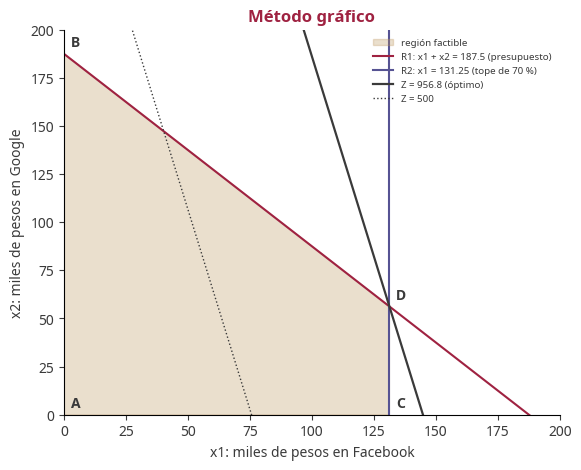

In [3]:
B_MILES = 250 * 9 / 12                                       # presupuesto de los 9 meses, en miles de pesos
TOPE = 0.70 * B_MILES                                          # tope de 70 % en un canal
rF, rG = r["Facebook"] * 1000, r["Google"] * 1000              # visitantes por cada mil pesos
vertices = pd.DataFrame({"vértice": ["A", "B", "C", "D"], "x1_facebook": [0, 0, TOPE, TOPE],
                         "x2_google": [0, B_MILES, 0, B_MILES - TOPE]})
vertices["Z_visitantes"] = rF * vertices.x1_facebook + rG * vertices.x2_google
print(f"Z = {rF:.3f} x1 + {rG:.3f} x2")

fig, ax = plt.subplots(figsize=(6.4, 5))
ax.fill([0, 0, TOPE, TOPE], [0, B_MILES, B_MILES - TOPE, 0], color=DORADO, alpha=0.3, label="región factible")
xs = np.linspace(0, 200, 50)
ax.plot(xs, B_MILES - xs, color=GUINDA, label="R1: x1 + x2 = 187.5 (presupuesto)")
ax.axvline(TOPE, color=PALETA[2], label="R2: x1 = 131.25 (tope de 70 %)")
zmax = vertices.Z_visitantes.max()
ax.plot(xs, (zmax - rF * xs) / rG, color=GRIS, lw=1.6, label=f"Z = {zmax:.1f} (óptimo)")
ax.plot(xs, (500 - rF * xs) / rG, color=GRIS, lw=1, ls=":", label="Z = 500")
for v in vertices.itertuples():
    ax.annotate(v.vértice, (v.x1_facebook, v.x2_google), xytext=(5, 5), textcoords="offset points", weight="bold")
ax.set_xlim(0, 200); ax.set_ylim(0, 200)
ax.set_xlabel("x1: miles de pesos en Facebook"); ax.set_ylabel("x2: miles de pesos en Google")
ax.legend(frameon=False, fontsize=7, loc="upper right"); ax.set_title("Método gráfico")
guardar(fig, "6_metodo_grafico")
vertices.round(2)

El óptimo es el vértice **D**: Facebook se lleva todo lo que el tope le permite (131,250 pesos) y el resto
va a Google (56,250), porque gastarlo rinde más que dejarlo sin usar. Son unos 957 visitantes.

Guardamos el mismo modelo en un Excel con fórmulas, listo para resolverse también con **Solver** (como en las prácticas
de la materia): celdas de decisión, función objetivo, restricciones y la tabla de vértices.

In [4]:
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill

wb = Workbook(); ws = wb.active; ws.title = "Modelo"
blanco, guinda, gris = Font(bold=True, color="FFFFFF"), PatternFill("solid", fgColor="9F2241"), PatternFill("solid", fgColor="E6E6E6")
filas = [["Torre del Caribe · Presupuesto en dos canales (método gráfico)"], [],
         ["Parámetro", "Valor", "De dónde sale"],
         ["Visitantes por cada mil pesos en Facebook (rF)", round(rF, 6), "conversión ÷ (clic en dólares × pesos por dólar)"],
         ["Visitantes por cada mil pesos en Google (rG)", round(rG, 6), "WordStream 2025, categoría viajes; FRED"],
         ["Presupuesto de 9 meses (miles de pesos)", "=250*9/12", "$250,000 al año prorrateado"],
         ["Tope por canal", 0.7, "no depender de una sola plataforma"], [],
         ["Decisión", "Miles de pesos", "Para Solver: celdas que cambian"],
         ["x1 Facebook", TOPE], ["x2 Google", B_MILES - TOPE], [],
         ["Función objetivo Z (visitantes)", "=B4*B10+B5*B11", "Solver: maximizar esta celda"], [],
         ["Restricción", "Lado izquierdo", "Límite"],
         ["R1 presupuesto: x1 + x2 ≤ B6", "=B10+B11", "=B6"], ["R2 tope de Facebook: x1 ≤ 0.7·B6", "=B10", "=B7*B6"], [],
         ["Vértice", "x1", "x2", "Z"]]
for f in filas:
    ws.append(f)
for i, (v, x1, x2) in enumerate([("A", 0, 0), ("B", 0, "=B6"), ("C", "=B7*B6", 0), ("D", "=B7*B6", "=B6-B7*B6")], start=20):
    ws.append([v, x1, x2, f"=$B$4*B{i}+$B$5*C{i}"])
for fila in (3, 9, 15, 19):
    for celda in ws[fila]:
        celda.font, celda.fill = blanco, guinda
for celda in ("B10", "B11", "B13"):
    ws[celda].fill = gris
ws["A1"].font = Font(bold=True, size=13, color="9F2241")
for col, ancho in zip("ABCD", (48, 16, 44, 14)):
    ws.column_dimensions[col].width = ancho
wb.save(Path.cwd() / "6_Metodo_grafico.xlsx")
print("Excel guardado: 6_Metodo_grafico.xlsx")

Excel guardado: 6_Metodo_grafico.xlsx


## 3. El modelo completo: estocástico de dos etapas
El modelo chico no dice **a qué lugar ni en qué mes** va el dinero. El completo sí, y además toma en cuenta que el
futuro es incierto.

**Conjuntos.** Meses $m$: los 9 que tienen calendario y escenarios para los tres lugares (no se extrapola). Lugares $l$:
Chetumal, Bahía, Ruta. Canales $c$: Google y Facebook. Escenarios $s$: malo, probable y bueno (p10, p50 y p90 del Monte
Carlo del notebook 5), con probabilidades 0.3, 0.4 y 0.3 (la **regla de Swanson** para resumir una distribución con tres
percentiles).

| Variable | Tipo | Qué decide | Cuándo |
|---|---|---|---|
| $x_{m,l,c} \ge 0$ | continua | pesos en el mes, lugar y canal | hoy (etapa 1) |
| $y_{s,m,l} \in \{0,1\}$ | binaria | si el anuncio sigue encendido (1) o se pausa (0) | al ver el escenario (etapa 2) |
| $w_{s,m,l} \ge 0$ | continua | visitantes que sí llegan por la campaña | al ver el escenario |

Visitantes que trae la campaña: $v_{m,l} = r_G x_{m,l,G} + r_F x_{m,l,F}$. **Objetivo:**
$\max \sum_s p_s \sum_{m,l} w_{s,m,l}$ (los visitantes esperados).

| # | Restricción | En palabras |
|---|---|---|
| R1 | $\sum x \le 187{,}500$ | No gastar más del presupuesto |
| R2 | $x_{m,l,c} = 0$ si $(m,l)$ es temporada alta | Cero anuncio donde ya está lleno |
| R3 | $D^{p50}_{m,l} + v_{m,l} \le C_l$ | En el escenario probable no se rebasa la capacidad probada |
| R4 | $\sum_{m,c} x_{m,l,c} \ge 0.15 \times 187{,}500$ | Piso de equidad: cada lugar recibe al menos 15 % |
| R5 | $\sum_{m,l} x_{m,l,c} \le 0.70 \times 187{,}500$ | Ningún canal pasa de 70 % |
| R6 | $D_{s,m,l} + v_{m,l} \le C_l + M_{s,m,l}(1-y_{s,m,l})$ | Si en un escenario se rebasaría la capacidad, el anuncio se pausa |
| R7 | $w \le v$ y $w \le U y$ | Solo cuentan los visitantes de anuncios encendidos |

**La "M grande".** Si $y = 1$, R6 exige respetar la capacidad; si $y = 0$, $M$ la desactiva pero R7 deja $w = 0$: esos
visitantes se pierden. Usamos la $M$ más chica que funciona, $M = \max(D + U - C, 0)$, porque una $M$ enorme vuelve
lento e inestable al solucionador.

Primero armamos la tabla de lugar × mes con el nivel de temporada, la capacidad probada y los tres escenarios.

In [5]:
import pulp

SUR = ["Chetumal", "Bahía Calderitas–Oxtankah", "Ruta arqueológica del sur"]
ESCENARIOS = {"malo": ("malo_p10_est", 0.3), "probable": ("probable_p50_est", 0.4), "bueno": ("bueno_p90_est", 0.3)}

def tabla_meses(golpe=0.0):
    cal = pd.read_parquet(GOLD / "pronostico_calendario.parquet")
    cal = cal[cal.lugar.isin(SUR)][["lugar", "periodo", "nivel"]]
    esc = pd.read_parquet(GOLD / "pronostico_escenarios.parquet")
    esc = esc[esc.lugar.isin(SUR) & (esc.golpe_tormenta_supuesto == golpe)]
    tm = cal.merge(esc[["lugar", "periodo", "capacidad_probada", "riesgo_rebasar_capacidad"] + [c for c, _ in ESCENARIOS.values()]],
                   on=["lugar", "periodo"], how="inner")
    completos = tm.groupby("periodo").lugar.nunique()
    tm = tm[tm.periodo.isin(completos[completos == len(SUR)].index)].sort_values(["periodo", "lugar"])   # meses con los 3 lugares
    tm["libre"] = 1 - tm.probable_p50_est / tm.capacidad_probada        # fracción de la capacidad que queda libre
    return tm.reset_index(drop=True)

tm = tabla_meses()
print(f"{tm.periodo.nunique()} meses ({tm.periodo.min():%m-%Y} a {tm.periodo.max():%m-%Y}) × {len(SUR)} lugares; "
      f"en temporada alta: {(tm.nivel == 'alta').sum()} combinaciones")
tm.pivot(index="periodo", columns="lugar", values="libre").round(2)

9 meses (10-2026 a 06-2027) × 3 lugares; en temporada alta: 7 combinaciones


lugar,Bahía Calderitas–Oxtankah,Chetumal,Ruta arqueológica del sur
periodo,,,
2026-10-01,0.57,0.18,0.65
2026-11-01,0.57,0.15,0.48
2026-12-01,0.15,0.04,0.30
2027-01-01,0.26,0.24,0.14
2027-02-01,0.40,0.30,0.39
2027-03-01,0.34,0.18,0.34
2027-04-01,0.22,0.16,0.46
2027-05-01,0.50,0.26,0.67
2027-06-01,0.59,0.26,0.69


### Cómo lo resuelve la computadora
Escribimos el modelo con **PuLP** y lo resuelve **CBC** (software libre). Como las $y$ son 0 o 1, CBC usa
**ramificación y acotamiento**: resuelve la versión con $y$ continua por **simplex** (que salta de vértice en vértice,
la misma idea del método gráfico en muchas dimensiones), y si alguna $y$ sale fraccionaria crea dos subproblemas
($y = 0$ y $y = 1$) y descarta las ramas que ya no pueden mejorar la mejor solución entera.

**Desempate en dos pasos.** Como todos los lugares convierten igual (no hay dato de respuesta por lugar), hay muchísimas
soluciones con el mismo máximo; CBC entregaba una cualquiera, con todo el dinero de cada lugar en un solo mes. Por eso:
**paso 1**, encontrar el máximo $z^*$; **paso 2**, exigir al menos $z^*$ y, entre esas soluciones, quedarse con la que
reparte cada canal **en proporción al espacio libre** de cada mes y lugar,
$\pi_{m,l} = \text{libre}_{m,l} / \sum \text{libre}$, minimizando $\sum |x - \pi \cdot \text{canal}|$ (el valor absoluto se
vuelve lineal con $d \ge x - \text{meta}$ y $d \ge \text{meta} - x$).

In [6]:
import time
from dataclasses import dataclass, replace

@dataclass(frozen=True)
class Supuestos:
    presupuesto_anual: float = 250_000.0
    cvr_facebook: float | None = None
    cpc_facebook_usd: float | None = None
    golpe_tormenta: float = 0.0
    piso_equidad: float = 0.15
    tope_canal: float = 0.70
    temporada_alta: bool = True
    capacidad: bool = True
    equidad: bool = True
    canales: bool = True
    ocupacion_max: float | None = None
    nombre: str = "Base"

def resolver(s=Supuestos(), desempatar=True):
    tm = tabla_meses(s.golpe_tormenta)
    B = s.presupuesto_anual * tm.periodo.nunique() / 12                 # prorrateo a los meses con pronóstico
    rc = rendimiento(s.cvr_facebook, s.cpc_facebook_usd)
    filas = {(f.periodo, f.lugar): f for f in tm.itertuples()}
    idx = list(filas)
    U = max(rc.values()) * B                                           # lo más que podría traer una celda
    m = pulp.LpProblem("presupuesto", pulp.LpMaximize)
    x = {(p, l, c): pulp.LpVariable(f"x_{i}_{c}", lowBound=0) for i, (p, l) in enumerate(idx) for c in rc}
    y = {(e, p, l): pulp.LpVariable(f"y_{e}_{i}", cat="Binary") for e in ESCENARIOS for i, (p, l) in enumerate(idx)}
    w = {(e, p, l): pulp.LpVariable(f"w_{e}_{i}", lowBound=0) for e in ESCENARIOS for i, (p, l) in enumerate(idx)}
    conv = {(p, l): pulp.lpSum(rc[c] * x[p, l, c] for c in rc) for (p, l) in idx}
    m += (pulp.lpSum(x.values()) <= B, "presupuesto")                                          # R1
    for (p, l), f in filas.items():
        i = idx.index((p, l))
        if s.temporada_alta and f.nivel == "alta":
            for c in rc:
                x[p, l, c].upBound = 0                                                        # R2
        if s.capacidad:
            m += (conv[p, l] <= f.capacidad_probada - f.probable_p50_est, f"cap_{i}")         # R3
        if s.ocupacion_max is not None:                                                       # frontera de Pareto
            holgura = s.ocupacion_max * f.capacidad_probada - f.probable_p50_est
            if holgura <= 0:
                for c in rc:
                    x[p, l, c].upBound = 0
            else:
                m += (conv[p, l] <= holgura, f"pareto_{i}")
        for e, (col, _) in ESCENARIOS.items():
            D = getattr(f, col)
            M = max(D + U - f.capacidad_probada, 0)                                           # la M más chica que sirve
            m += (D + conv[p, l] <= f.capacidad_probada + M * (1 - y[e, p, l]), f"rec_{e}_{i}")   # R6
            m += (w[e, p, l] <= conv[p, l], f"w1_{e}_{i}")                                     # R7
            m += (w[e, p, l] <= U * y[e, p, l], f"w2_{e}_{i}")
    sin_meses = [l for l in SUR if all(x[p, l2, c].upBound == 0 for (p, l2, c) in x if l2 == l)]
    if s.equidad:
        for l in SUR:
            if l not in sin_meses:
                m += (pulp.lpSum(x[p, l2, c] for (p, l2, c) in x if l2 == l) >= s.piso_equidad * B, f"equidad_{SUR.index(l)}")   # R4
    if s.canales:
        for c in rc:
            m += (pulp.lpSum(x[p, l, c2] for (p, l, c2) in x if c2 == c) <= s.tope_canal * B, f"canal_{c}")                # R5
    esperado = pulp.lpSum(ESCENARIOS[e][1] * w[e, p, l] for (e, p, l) in w)
    m.setObjective(esperado)                                                                  # paso 1
    m.solve(pulp.PULP_CBC_CMD(msg=False))
    if pulp.LpStatus[m.status] != "Optimal":
        return {"estado": pulp.LpStatus[m.status]}
    z1 = pulp.value(esperado)
    if desempatar:                                                                            # paso 2
        m += (esperado >= z1 * (1 - 1e-7), "lexicografico")
        permitida = {k: (x[k + (next(iter(rc)),)].upBound != 0) and f.bueno_p90_est < f.capacidad_probada for k, f in filas.items()}
        total_libre = sum(filas[k].libre for k in idx if permitida[k])
        d = {k: pulp.LpVariable(f"d_{idx.index(k[:2])}_{k[2]}", lowBound=0) for k in x}
        for (p, l, c) in x:
            meta = (filas[p, l].libre / total_libre if permitida[p, l] else 0.0) * pulp.lpSum(x[p2, l2, c] for (p2, l2, c2) in x if c2 == c)
            m += (d[p, l, c] >= x[p, l, c] - meta, f"d1_{idx.index((p, l))}_{c}")
            m += (d[p, l, c] >= meta - x[p, l, c], f"d2_{idx.index((p, l))}_{c}")
        m.setObjective(-pulp.lpSum(d.values()))
        m.solve(pulp.PULP_CBC_CMD(msg=False))
    plan = pd.DataFrame([{"periodo": p, "lugar": l, "canal": c, "pesos": x[p, l, c].value() or 0.0} for (p, l, c) in x])
    return {"estado": "Optimal", "visitantes": pulp.value(esperado), "plan": plan, "B": B, "modelo": m, "y": y, "z1": z1,
            "n_variables": (len(x), len(y), len(w))}

inicio = time.time()
sol = resolver()
print(f"{sol['n_variables'][0]} variables x, {sol['n_variables'][1]} binarias y, {sol['n_variables'][2]} variables w · "
      f"resuelto en {time.time() - inicio:.1f} s · visitantes esperados: {sol['visitantes']:.1f}")
coincide("plan de presupuesto (pesos por mes, lugar y canal)", sol["plan"].pesos,
         pd.read_parquet(GOLD / "presupuesto_plan.parquet").pesos, tolerancia=0.01)
reparto = sol["plan"].groupby("lugar").pesos.sum()
print("Reparto por lugar:", (reparto / sol["B"] * 100).round(1).to_dict(), "· por canal:",
      (sol["plan"].groupby("canal").pesos.sum() / sol["B"] * 100).round(1).to_dict())

54 variables x, 81 binarias y, 81 variables w · resuelto en 0.5 s · visitantes esperados: 956.8
✓ plan de presupuesto (pesos por mes, lugar y canal): coincide con el proyecto (diferencia máxima 0)
Reparto por lugar: {'Bahía Calderitas–Oxtankah': 36.9, 'Chetumal': 21.6, 'Ruta arqueológica del sur': 41.5} · por canal: {'Facebook': 70.0, 'Google': 30.0}


Ejemplo a mano, la Ruta en 10-2026: libre = 1 − 3,688 / 10,465 = 0.6476


lugar,Bahía Calderitas–Oxtankah,Chetumal,Ruta arqueológica del sur
periodo,,,
2026-10-01,13276.0,4133.0,15177.0
2026-11-01,13293.0,3574.0,11145.0
2026-12-01,0.0,0.0,0.0
2027-01-01,0.0,5650.0,0.0
2027-02-01,9300.0,6916.0,9123.0
2027-03-01,7863.0,4209.0,0.0
2027-04-01,0.0,3821.0,10675.0
2027-05-01,11610.0,6141.0,15608.0
2027-06-01,13833.0,6091.0,16061.0


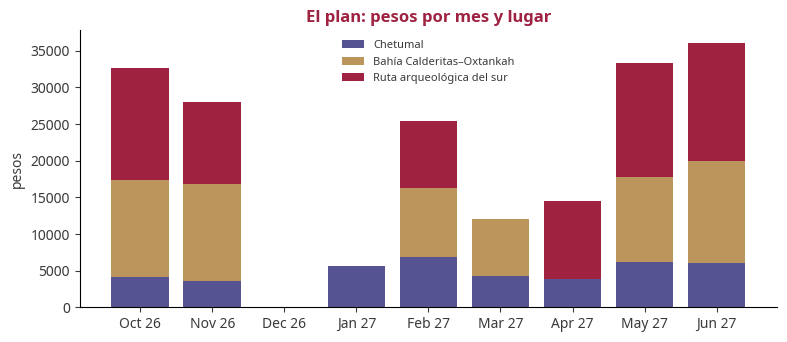

In [7]:
tabla = sol["plan"].pivot_table(index="periodo", columns="lugar", values="pesos", aggfunc="sum")
fig, ax = plt.subplots(figsize=(9, 3.6))
abajo = np.zeros(len(tabla))
for lugar, color in zip(SUR, [PALETA[2], DORADO, GUINDA]):
    ax.bar(tabla.index.strftime("%b %y"), tabla[lugar], bottom=abajo, color=color, label=lugar)
    abajo += tabla[lugar].to_numpy()
ax.set_ylabel("pesos"); ax.legend(frameon=False, fontsize=8); ax.set_title("El plan: pesos por mes y lugar")
guardar(fig, "6_plan_presupuesto")
ruta_oct = tm[(tm.lugar == "Ruta arqueológica del sur")].iloc[0]
print(f"Ejemplo a mano, la Ruta en {ruta_oct.periodo:%m-%Y}: libre = 1 − {ruta_oct.probable_p50_est:,.0f} / "
      f"{ruta_oct.capacidad_probada:,.0f} = {ruta_oct.libre:.4f}")
tabla.round(0)

**Lectura.** Las 7 combinaciones de temporada alta quedan en cero: diciembre en los tres lugares, enero en
la Bahía y la Ruta, marzo en la Ruta y abril en la Bahía. El dinero se reparte
en proporción al espacio libre, por eso la Ruta y la Bahía, con más capacidad libre, reciben más que Chetumal.

**Por qué "estocástico de dos etapas".** La decisión de hoy ($x$) se toma sin saber qué escenario va a pasar; la
reacción ($y$) depende del escenario. Al maximizar el promedio sobre escenarios, el modelo aprende desde hoy a no gastar
en meses en que un año bueno llenaría el lugar, porque ese dinero se perdería con probabilidad 0.3. Aquí se juntan las
dos materias: la incertidumbre de Modelos Estocásticos entra a la optimización de Investigación de Operaciones.

**Qué descartamos.** Un modelo **determinista** con solo el escenario probable: no sabría que en un año bueno el
anuncio tendría que pausarse. **Maximizar la derrama económica**: SITUR-Q no trae unidades y la serie termina en 2024.
**Visitantes con castigo por saturación**: exige elegir un peso arbitrario entre visitantes y presión; en su lugar
trazamos la frontera de Pareto (abajo), que muestra el intercambio sin inventar ese peso.

## 4. ¿Cuánto cuesta cada regla?
Resolvemos el modelo **sin** cada regla y comparamos. Luego los **precios sombra**: cuántos visitantes más traería
aflojar una restricción en una unidad, $\lambda_i = \partial z^* / \partial b_i$. Para calcularlos se fijan las binarias
en su valor óptimo y se resuelve el problema lineal que queda.

In [8]:
v0 = sol["visitantes"]
filas = []
for regla, texto in [("temporada_alta", "Cero anuncio en temporada alta"), ("capacidad", "Tope de capacidad probada"),
                     ("equidad", "Piso de equidad de 15 % por lugar"), ("canales", "Tope de 70 % por canal")]:
    v = resolver(replace(Supuestos(), **{regla: False}))["visitantes"]
    filas.append({"regla": texto, "visitantes sin la regla": v, "cuesta (visitantes)": v - v0, "cuesta (%)": (v / v0 - 1) * 100})
reglas = pd.DataFrame(filas)
coincide("costo de cada regla", reglas["cuesta (visitantes)"], pd.read_parquet(GOLD / "presupuesto_reglas.parquet").costo_visitantes, tolerancia=1e-4)

base = resolver(desempatar=False)                                   # precios sombra: binarias fijas y LP del paso 1
mm = base["modelo"]
for v in base["y"].values():
    v.lowBound = v.upBound = round(v.value()); v.cat = pulp.LpContinuous
mm.solve(pulp.PULP_CBC_CMD(msg=False))
sombra = pd.DataFrame([{"regla": n, "precio sombra": cc.pi, "holgura": cc.slack} for n, cc in mm.constraints.items()
                       if n.startswith(("presupuesto", "equidad", "canal"))])
coincide("precios sombra", sombra["precio sombra"], pd.read_parquet(GOLD / "presupuesto_precios_sombra.parquet").precio_sombra, tolerancia=1e-6)
print(reglas.round(1).to_string(index=False)); sombra

✓ costo de cada regla: coincide con el proyecto (diferencia máxima 0)
✓ precios sombra: coincide con el proyecto (diferencia máxima 0)
                            regla  visitantes sin la regla  cuesta (visitantes)  cuesta (%)
   Cero anuncio en temporada alta                    956.8                  0.0         0.0
        Tope de capacidad probada                    956.8                  0.0         0.0
Piso de equidad de 15 % por lugar                    956.8                  0.0         0.0
           Tope de 70 % por canal                   1239.1                282.3        29.5


,regla,precio sombra,holgura
0,presupuesto,0.001590,-0.0
1,equidad_0,-0.000000,-0.0
2,equidad_1,-0.000000,-0.0
3,equidad_2,-0.000000,-103125.0
4,canal_Google,-0.000000,75000.0
5,canal_Facebook,0.005019,-0.0


**Lectura.**
- El **tope de 70 % por canal** es la única regla que cuesta: sin ella el modelo pondría todo en Facebook y traería 282
  visitantes más (29.5 %). La mantenemos por riesgo: depender de una sola plataforma deja la campaña expuesta a que esa
  plataforma suba precios o cambie sus reglas, y su conversión es el supuesto menos seguro del modelo.
- El **precio sombra del presupuesto** es 0.00159 visitantes por peso, justo el rendimiento de Google: un peso extra iría
  a Google, porque Facebook ya está en su tope. El del tope de Facebook es 0.006608 − 0.001590 = 0.005019.
- **Equidad y capacidad tienen precio sombra 0** (holgura complementaria: una restricción que no aprieta no tiene
  precio). Con este presupuesto, ni la regla ambiental ni la social le cuestan visitantes a la campaña.

### La frontera de Pareto: visitantes contra presión
Si exigimos que ningún mes con anuncio pase de $\varepsilon$ veces su capacidad en el escenario probable
($D^{p50} + v \le \varepsilon C$), ¿cuántos visitantes trae la campaña? Es el método de la **ε-restricción**.

✓ frontera de Pareto: coincide con el proyecto (diferencia máxima 0)


,ocupación máxima,visitantes
0,1.00,956.8
1,0.90,956.8
2,0.80,956.8
3,0.70,956.8
4,0.60,956.8
5,0.50,956.8
6,0.45,956.8
7,0.40,956.8
8,0.35,536.9
9,0.30,0.0


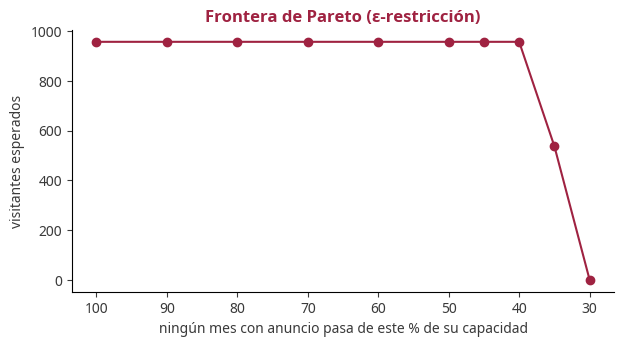

In [9]:
topes = (1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.45, 0.4, 0.35, 0.3)
par = pd.DataFrame([{"ocupación máxima": e, "visitantes": resolver(replace(Supuestos(), ocupacion_max=e)).get("visitantes")}
                    for e in topes])
coincide("frontera de Pareto", par.visitantes.fillna(0), pd.read_parquet(GOLD / "presupuesto_pareto.parquet").visitantes_esperados.fillna(0), tolerancia=1e-4)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(par["ocupación máxima"] * 100, par.visitantes, marker="o", color=GUINDA)
ax.invert_xaxis(); ax.set_xlabel("ningún mes con anuncio pasa de este % de su capacidad"); ax.set_ylabel("visitantes esperados")
ax.set_title("Frontera de Pareto (ε-restricción)")
guardar(fig, "6_pareto")
par.round({"visitantes": 1})

Hasta un tope de 40 % no se pierde ningún visitante: la campaña puede prometer que **ningún mes con anuncio
pasará del 40 % de su capacidad probada, sin costo**. Con 35 % ya se pierden visitantes y con 30 % no queda ningún mes
posible.

## 5. Sensibilidad: ¿y si los supuestos están mal?

In [10]:
casos = [Supuestos(), Supuestos(cvr_facebook=0.03, nombre="Conversión Facebook 3 %"),
         Supuestos(cvr_facebook=cvr_fb_mediana, nombre=f"Conversión Facebook {cvr_fb_mediana:.2%} (mediana de industrias)"),
         Supuestos(cpc_facebook_usd=float(t["localiq_facebook_2026", "Average CPC"]), nombre="Clic de Facebook más barato (LocaliQ 2026)"),
         Supuestos(golpe_tormenta=0.25, nombre="Golpe de tormenta 25 %"), Supuestos(golpe_tormenta=0.5, nombre="Golpe de tormenta 50 %"),
         Supuestos(presupuesto_anual=500_000, nombre="Presupuesto $500,000"), Supuestos(presupuesto_anual=1_000_000, nombre="Presupuesto $1,000,000")]
filas = []
for s in casos:
    so = resolver(s)
    lug = so["plan"].groupby("lugar").pesos.sum() / so["B"] * 100
    filas.append({"caso": s.nombre, "visitantes": so["visitantes"], "pesos por visitante": so["B"] / so["visitantes"],
                  **{f"% {l.split(' ')[0]}": lug[l] for l in SUR}})
sens = pd.DataFrame(filas)
coincide("sensibilidad (visitantes)", sens.visitantes, pd.read_parquet(GOLD / "presupuesto_sensibilidad.parquet").visitantes_esperados, tolerancia=1e-4)
sens.round(1)

✓ sensibilidad (visitantes): coincide con el proyecto (diferencia máxima 0)


,caso,visitantes,pesos por visitante,% Chetumal,% Bahía,% Ruta
0,Base,956.8,196.0,21.6,36.9,41.5
1,Conversión Facebook 3 %,542.0,346.0,21.6,36.9,41.5
2,Conversión Facebook 6.38% (mediana de industrias),1051.8,178.3,21.6,36.9,41.5
3,Clic de Facebook más barato (LocaliQ 2026),1142.6,164.1,21.6,36.9,41.5
4,Golpe de tormenta 25 %,956.8,196.0,22.0,36.8,41.2
5,Golpe de tormenta 50 %,956.8,196.0,21.9,36.9,41.2
6,"Presupuesto $500,000",1913.6,196.0,21.6,36.9,41.5
7,"Presupuesto $1,000,000",3827.1,196.0,21.6,36.9,41.5


Los visitantes cambian con la conversión de Facebook (de 542 a 1,052), pero **el reparto entre lugares
casi no se mueve**: la recomendación es estable aunque el supuesto más débil esté mal. Con más presupuesto los
visitantes crecen en proporción, porque el modelo es lineal y la capacidad no se alcanza.

### ¿Por qué un piso de 15 % y un tope de 70 %?
Son reglas de política, no datos, así que las probamos con varios valores para ver qué cuestan.

In [11]:
filas = []
for piso in (0.0, 0.15, 0.25, 1 / 3):
    so = resolver(replace(Supuestos(), piso_equidad=piso), desempatar=False)
    filas.append({"regla": "piso de equidad", "valor": f"{piso:.0%}", "visitantes": so.get("visitantes"), "estado": so["estado"]})
for tope in (0.5, 0.6, 0.7, 0.8, 1.0):
    so = resolver(replace(Supuestos(), tope_canal=tope), desempatar=False)
    filas.append({"regla": "tope por canal", "valor": f"{tope:.0%}", "visitantes": so.get("visitantes"), "estado": so["estado"]})
pd.DataFrame(filas).round(1)

,regla,valor,visitantes,estado
0,piso de equidad,0%,956.8,Optimal
1,piso de equidad,15%,956.8,Optimal
2,piso de equidad,25%,956.8,Optimal
3,piso de equidad,33%,956.8,Optimal
4,tope por canal,50%,768.6,Optimal
5,tope por canal,60%,862.7,Optimal
6,tope por canal,70%,956.8,Optimal
7,tope por canal,80%,1050.9,Optimal
8,tope por canal,100%,1239.1,Optimal


**Piso de equidad.** Cualquier piso hasta un tercio (el reparto igual) cuesta **cero visitantes**: hay
espacio en los tres lugares. Elegimos 15 %, la mitad de un reparto igual, porque garantiza que ninguna comunidad se
quede fuera sin obligar al modelo a repartir parejo cuando un lugar tiene mucho más espacio que otro. Lo que sí hace el
piso es proteger el resultado si cambian los datos: con un pronóstico distinto, sin piso, el modelo podría mandar todo a
un solo lugar y solo trasladar la saturación.

**Tope por canal.** Cada 10 puntos de tope le dan a Facebook más dinero y suben los visitantes, porque en el caso base
Facebook rinde cuatro veces más. Elegimos 70 %: deja a Facebook como canal principal y conserva 30 % en Google, que
alcanza a quien ya está buscando viajar. Con 100 % la campaña dependería de un solo supuesto (la conversión de Facebook,
que no está publicada para turismo): si la conversión real fuera 3 %, todo el dinero estaría en el canal equivocado.

## 6. La etapa 2 semana a semana: el motor de la Torre
El modelo decide el dinero de cada mes. Cada semana, la Torre en vivo (que corre con Spark Structured Streaming, notebook
1) decide para cada lugar: **temporada alta** (no se gasta), **fuera del plan**, **pausado** (tormenta cerca, clima raro
o llegó más gente de la esperada) o **encendido**. El dinero pausado no se pierde: pasa a la siguiente semana permitida.

$$b = \frac{\text{pesos del mes}}{\text{lunes del mes}}, \qquad \text{gasto}_w = \begin{cases} b + A_{w-1} & \text{si está encendido} \\ 0 & \text{si no} \end{cases}$$

donde $A_w$ es el dinero acumulado: sube $b$ cuando la semana se pausa y vuelve a 0 cuando se enciende. Aquí corremos
las 239 semanas reales en orden, con las mismas reglas.

In [12]:
senales = pd.read_parquet(GOLD / "envivo_senales.parquet")
plan_mes = pd.read_parquet(GOLD / "presupuesto_plan.parquet").assign(mes=lambda z: pd.to_datetime(z.periodo).dt.month)
tm_ = tm.assign(mes=tm.periodo.dt.month)
alta = {(f.mes, f.lugar) for f in tm_.itertuples() if f.nivel == "alta"}
pesos_mes = {k: v for k, v in plan_mes.groupby(["mes", "lugar"]).pesos.sum().items() if k not in alta}
libre = {(f.mes, f.lugar): f.libre for f in tm_.itertuples()}
CLAVE = {"Chetumal": "chetumal", "Bahía Calderitas–Oxtankah": "bahia", "Ruta arqueológica del sur": "ruta"}
PUNTO = {"Chetumal": "chetumal", "Bahía Calderitas–Oxtankah": "chetumal", "Ruta arqueológica del sur": "kohunlich"}

def lunes_del_mes(semana):
    dias = pd.date_range(semana.replace(day=1), semana + pd.offsets.MonthEnd(0), freq="D")
    return int((dias.weekday == 0).sum())

arrastre = {l: 0.0 for l in SUR}                                  # el dinero pausado que todavía no se gasta
decisiones = []
for fila in senales.sort_values("semana").to_dict("records"):     # una semana a la vez, en orden
    fila = {k: (None if not isinstance(v, (list, dict)) and pd.isna(v) else v) for k, v in fila.items()}
    semana = pd.Timestamp(fila["semana"]); mes = semana.month
    for lugar in SUR:
        if (mes, lugar) in alta:
            accion, gasto = "temporada alta", 0.0
        elif (mes, lugar) not in pesos_mes:
            accion, gasto = "fuera del plan", 0.0
        else:
            semanal = pesos_mes[mes, lugar] / lunes_del_mes(semana)
            pausa = (fila.get("tormenta") is True or fila.get(f"{PUNTO[lugar]}_clima_raro") is True
                     or fila.get(f"{CLAVE[lugar]}_llegadas") == "arriba")      # las tres razones para pausar
            if pausa:
                arrastre[lugar] += semanal; accion, gasto = "pausado", 0.0
            else:
                accion, gasto = "encendido", semanal + arrastre[lugar]; arrastre[lugar] = 0.0
        decisiones.append({"semana": semana, "lugar": lugar, "accion": accion, "pesos_gastados": gasto})
dec = pd.DataFrame(decisiones)
proyecto = pd.read_parquet(GOLD / "envivo_decisiones.parquet")
assert (dec.accion.to_numpy() == proyecto.accion.to_numpy()).all(), "las decisiones no coinciden"
coincide("pesos gastados cada semana", dec.pesos_gastados, proyecto.pesos_gastados, tolerancia=1e-6)
print(f"Pausas (lugar-semana): {(dec.accion == 'pausado').sum()} · dinero que quedó sin gastar al final: ${sum(arrastre.values()):,.0f}")
dec.pivot_table(index="lugar", columns="accion", values="semana", aggfunc="count", fill_value=0)

✓ pesos gastados cada semana: coincide con el proyecto (diferencia máxima 0)
Pausas (lugar-semana): 48 · dinero que quedó sin gastar al final: $0


accion,encendido,fuera del plan,pausado,temporada alta
lugar,,,,
Bahía Calderitas–Oxtankah,106,57,14,62
Chetumal,145,57,19,18
Ruta arqueológica del sur,104,57,15,63


**Lectura.** En las 239 semanas reales hubo 48 pausas y todo el dinero pausado se gastó después: pausar no
desperdicia el presupuesto, solo lo mueve a una semana mejor. Las llegadas **por debajo** de lo esperado no pausan: hay
espacio, que es lo que la campaña busca. Y si la semana no tiene dato de tormentas (2026 aún no se publica), no se pausa
por falta de evidencia, pero la página lo dice.

Las reglas del motor las elegimos entre varias opciones: **pausar y guardar el dinero** (elegida) contra **bajar el
gasto a la mitad** (se seguiría anunciando con mal clima) y **solo avisar** (la campaña no reaccionaría sola).

## 7. Resumen: todos los parámetros de este notebook

| Parámetro | Valor | Por qué | Qué descartamos |
|---|---|---|---|
| Objetivo | Visitantes esperados al sur | Es lo que la campaña busca y se puede medir | Derrama (sin dato usable); visitantes con castigo (peso arbitrario) |
| Presupuesto | $250,000 al año (supuesto) → $187,500 en 9 meses | No hay presupuesto real; se prueba con $500,000 y $1,000,000 | Extrapolar a meses sin pronóstico |
| Costo por clic y conversión | WordStream 2025, viajes (supuesto etiquetado) | El único dato publicado por categoría | Inventar un dato para México |
| Conversión de Facebook | La de Google (5.75 %) con barrido 3 % y mediana | No está publicada para turismo | Fijar un solo valor como dato |
| Escenarios | p10, p50, p90 con pesos 0.3, 0.4, 0.3 | Regla de Swanson para tres percentiles | Solo el escenario probable (determinista) |
| Temporada alta | Cero anuncio | No promover donde ya está lleno | Anunciar menos (seguiría empujando gente) |
| Capacidad | Mes más alto ya recibido | Lo único medido que existe | Capacidad física oficial (no existe) |
| Piso de equidad | 15 % por lugar | Mitad del reparto igual; cuesta 0 visitantes hasta 33 % | Sin piso (podría trasladar la saturación) |
| Tope por canal | 70 % | No depender de un supuesto; cuesta 282 visitantes | 100 % (todo en Facebook) |
| M grande | $\max(D + U - C, 0)$ | La más chica que funciona | Un número enorme (lento e inestable) |
| Desempate | Proporcional al espacio libre | Explicable; evita poner todo en un mes | Tope de 25 % por mes (otra regla arbitraria) |
| Motor semanal | Pausar y guardar el dinero | No se anuncia con mal clima y no se pierde dinero | Bajar a la mitad; solo avisar |

**Qué decisión alimenta.** Cuánto dinero va a cada lugar, mes y canal (las piezas del notebook 7) y qué hace la Torre
cada semana. Así el plan reparte la gente sin rebasar la capacidad de ningún lugar y sin dejar a ninguna comunidad
fuera, que es lo que pide el incidente crítico de la materia.